In [6]:
from pathlib import Path
import xarray as xr

data_dir = Path(r"C:\Users\chris\Documents\MAT 257\Project 2\Data")
nc_files = sorted(data_dir.glob("*.nc"))

# Longitude: 12°W to 4°E
# Latitude: 49°N to 61°N

def select_britain(ds):
    # Handle either ascending or descending latitude
    if ds.lat[0] < ds.lat[-1]:
        lat_slice = slice(49, 61)
    else:
        lat_slice = slice(61, 49)

    return ds.sel(
        lat=lat_slice,
        lon=slice(-12, 4)
    )

ds_gb = xr.open_mfdataset(
    nc_files,
    combine="by_coords",
    preprocess=select_britain,
    parallel=True,
    chunks={"time": 100}
)

print(ds_gb)

<xarray.Dataset> Size: 58MB
Dimensions:                  (time: 308, lat: 48, lon: 64)
Coordinates:
  * time                     (time) datetime64[ns] 2kB 2022-04-30 ... 2022-10-01
  * lat                      (lat) float32 192B 49.12 49.38 ... 60.62 60.88
  * lon                      (lon) float32 256B -11.88 -11.62 ... 3.625 3.875
Data variables: (12/17)
    sea_surface_temperature  (time, lat, lon) float32 4MB dask.array<chunksize=(2, 48, 64), meta=np.ndarray>
    sst_dtime                (time, lat, lon) float64 8MB dask.array<chunksize=(2, 48, 48), meta=np.ndarray>
    dt_analysis              (time, lat, lon) float32 4MB dask.array<chunksize=(2, 48, 64), meta=np.ndarray>
    sses_bias                (time, lat, lon) float32 4MB dask.array<chunksize=(2, 48, 64), meta=np.ndarray>
    sses_standard_deviation  (time, lat, lon) float32 4MB dask.array<chunksize=(2, 48, 64), meta=np.ndarray>
    diurnal_amplitude        (time, lat, lon) float32 4MB dask.array<chunksize=(2, 48, 64), meta

In [44]:
month_data = ds_gb[
    [
        "sea_surface_temperature",
        "wind_speed",
        "water_vapor"
    ]
].sel(
    time=slice("2022-07-01", "2022-07-31T23:59:59")
)

variables = [
    "sea_surface_temperature",
    "wind_speed",
    "water_vapor"
]

points_month = (
    month_data[variables]
    .to_dataframe()
    .reset_index()
    .rename(
        columns={
            "sea_surface_temperature": "temperature"
        }
    )
)

In [45]:
points_month

,time,lat,lon,temperature,wind_speed,water_vapor
0,2022-07-01,49.125,-11.875,NaN,NaN,15.899998
1,2022-07-01,49.125,-11.625,NaN,NaN,16.199997
2,2022-07-01,49.125,-11.375,NaN,NaN,16.499998
3,2022-07-01,49.125,-11.125,NaN,NaN,16.199997
4,2022-07-01,49.125,-10.875,NaN,NaN,16.199997
...,...,...,...,...,...,...
190459,2022-07-31,60.875,2.875,288.149994,4.199999,14.099998
190460,2022-07-31,60.875,3.125,290.699982,3.799999,13.799997
190461,2022-07-31,60.875,3.375,NaN,NaN,13.499998
190462,2022-07-31,60.875,3.625,NaN,NaN,12.599997


In [15]:
model_variables = [
    "temperature",
    "wind_speed",
    "water_vapor"
]

n_time_records = month_data.sizes["time"]

coverage = (
    month_points
    .groupby(["lat", "lon"])[model_variables]
    .count()
    / n_time_records
)

coverage["minimum_coverage"] = coverage.min(axis=1)

coverage.head()

temperature  wind_speed  water_vapor  minimum_coverage
lat    lon                                                            
49.125 -11.875     0.758065    0.790323     1.000000          0.758065
       -11.625     0.725806    0.774194     1.000000          0.725806
       -11.375     0.774194    0.790323     0.967742          0.774194
       -11.125     0.758065    0.790323     0.983871          0.758065
       -10.875     0.741935    0.790323     1.000000          0.741935

In [31]:
min_coverage = 0.20

eligible_coords = coverage[
    coverage["minimum_coverage"] >= min_coverage
].reset_index()

print("Eligible coordinates:", len(eligible_coords))

Eligible coordinates: 1409


In [27]:
len(month_points[["lat", "lon"]].drop_duplicates())

3072

<Axes: >

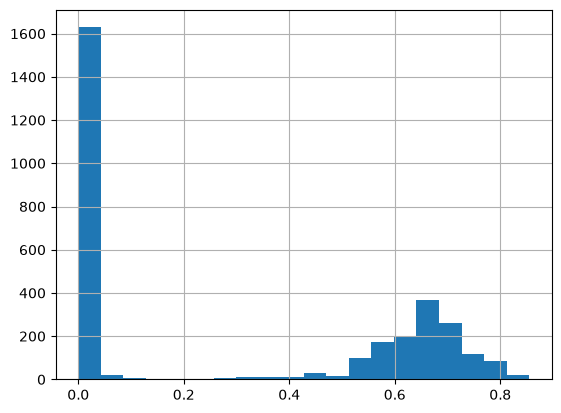

In [28]:
coverage["minimum_coverage"].hist(bins=20)

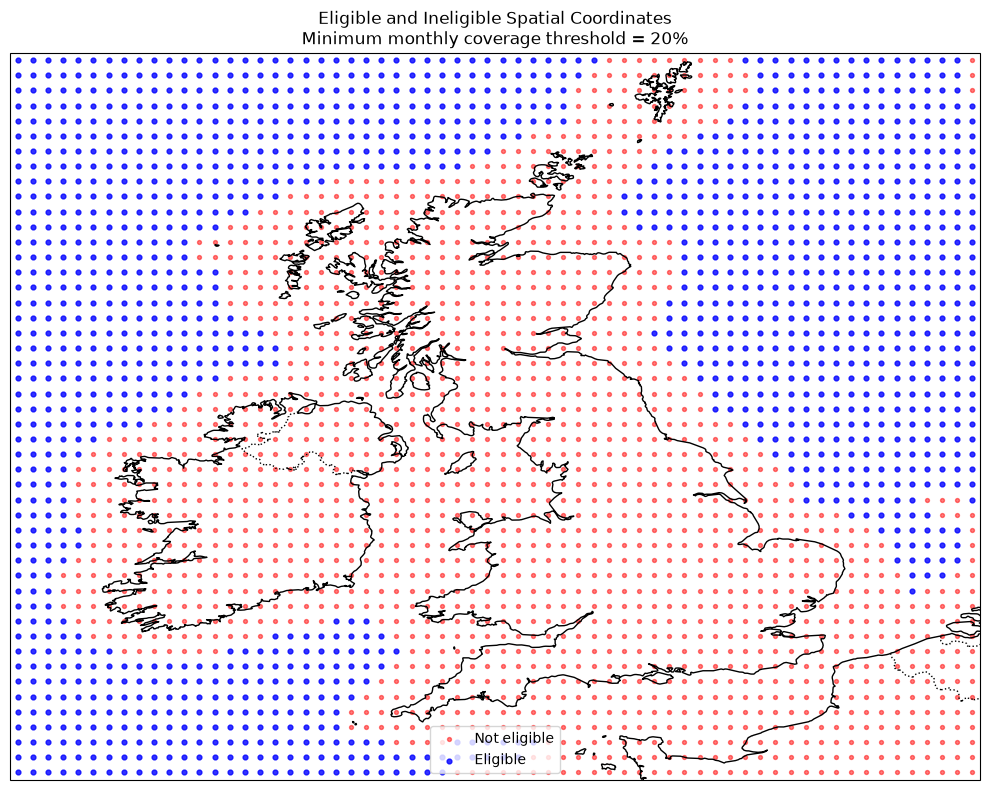

In [32]:
import numpy as np
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature

all_coords = month_points[
    ["lat", "lon"]
].drop_duplicates()

coverage_plot = (
    coverage["minimum_coverage"]
    .reset_index()
    .rename(columns={
        "minimum_coverage": "coverage"
    })
)

plot_coords = all_coords.merge(
    coverage_plot,
    on=["lat", "lon"],
    how="left"
)

min_coverage = 0.20

plot_coords["eligible"] = (
    plot_coords["coverage"] >= min_coverage
)

fig, ax = plt.subplots(
    figsize=(10, 8),
    subplot_kw={
        "projection": ccrs.PlateCarree()
    }
)

# Plot non-eligible points first
not_eligible = plot_coords[
    ~plot_coords["eligible"]
]

ax.scatter(
    not_eligible["lon"],
    not_eligible["lat"],
    color="red",
    s=8,
    alpha=0.5,
    transform=ccrs.PlateCarree(),
    label="Not eligible"
)

# Plot eligible points on top
eligible = plot_coords[
    plot_coords["eligible"]
]

ax.scatter(
    eligible["lon"],
    eligible["lat"],
    color="blue",
    s=12,
    alpha=0.8,
    transform=ccrs.PlateCarree(),
    label="Eligible"
)

ax.coastlines()
ax.add_feature(cfeature.BORDERS, linestyle=":")
ax.set_extent(
    [-12, 4, 49, 61],
    crs=ccrs.PlateCarree()
)

ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.set_title(
    "Eligible and Ineligible Spatial Coordinates\n"
    f"Minimum monthly coverage threshold = {min_coverage:.0%}"
)

ax.legend()
plt.tight_layout()
plt.show()

In [33]:
eligible_coords

,lat,lon,temperature,wind_speed,water_vapor,minimum_coverage
0,49.125,-11.875,0.758065,0.790323,1.000000,0.758065
1,49.125,-11.625,0.725806,0.774194,1.000000,0.725806
2,49.125,-11.375,0.774194,0.790323,0.967742,0.774194
3,49.125,-11.125,0.758065,0.790323,0.983871,0.758065
4,49.125,-10.875,0.741935,0.790323,1.000000,0.741935
...,...,...,...,...,...,...
1404,60.875,2.625,0.467742,0.483871,1.000000,0.467742
1405,60.875,2.875,0.483871,0.532258,1.000000,0.483871
1406,60.875,3.125,0.435484,0.500000,1.000000,0.435484
1407,60.875,3.375,0.354839,0.419355,1.000000,0.354839


In [46]:
points_month

,time,lat,lon,temperature,wind_speed,water_vapor
0,2022-07-01,49.125,-11.875,NaN,NaN,15.899998
1,2022-07-01,49.125,-11.625,NaN,NaN,16.199997
2,2022-07-01,49.125,-11.375,NaN,NaN,16.499998
3,2022-07-01,49.125,-11.125,NaN,NaN,16.199997
4,2022-07-01,49.125,-10.875,NaN,NaN,16.199997
...,...,...,...,...,...,...
190459,2022-07-31,60.875,2.875,288.149994,4.199999,14.099998
190460,2022-07-31,60.875,3.125,290.699982,3.799999,13.799997
190461,2022-07-31,60.875,3.375,NaN,NaN,13.499998
190462,2022-07-31,60.875,3.625,NaN,NaN,12.599997


In [61]:
cleaned = points_month.merge(eligible_coords[["lat", "lon", "minimum_coverage"]], how="inner", on=["lat", "lon"])
cleaned

,time,lat,lon,temperature,wind_speed,water_vapor,minimum_coverage
0,2022-07-01,49.125,-11.875,NaN,NaN,15.899998,0.758065
1,2022-07-01,49.125,-11.625,NaN,NaN,16.199997,0.725806
2,2022-07-01,49.125,-11.375,NaN,NaN,16.499998,0.774194
3,2022-07-01,49.125,-11.125,NaN,NaN,16.199997,0.758065
4,2022-07-01,49.125,-10.875,NaN,NaN,16.199997,0.741935
...,...,...,...,...,...,...,...
87353,2022-07-31,60.875,2.625,288.149994,4.400000,14.399998,0.467742
87354,2022-07-31,60.875,2.875,288.149994,4.199999,14.099998,0.483871
87355,2022-07-31,60.875,3.125,290.699982,3.799999,13.799997,0.435484
87356,2022-07-31,60.875,3.375,NaN,NaN,13.499998,0.354839


In [62]:
from pyproj import Transformer

transformer = Transformer.from_crs(
    "EPSG:4326",   # longitude/latitude
    "EPSG:3034",   # European Lambert Conformal Conic
    always_xy=True
)

cleaned["x"], cleaned["y"] = transformer.transform(
    cleaned["lon"].to_numpy(),
    cleaned["lat"].to_numpy()
)

# Get the day within the month
cleaned["time_days"] = (
    cleaned["time"] - cleaned["time"].min()
).dt.total_seconds() / (24 * 60 * 60)

cleaned

,time,lat,lon,temperature,wind_speed,water_vapor,minimum_coverage,x,y,time_days
0,2022-07-01,49.125,-11.875,NaN,NaN,15.899998,0.758065,2.480014e+06,2.717785e+06,0.0
1,2022-07-01,49.125,-11.625,NaN,NaN,16.199997,0.725806,2.496883e+06,2.712671e+06,0.0
2,2022-07-01,49.125,-11.375,NaN,NaN,16.499998,0.774194,2.513770e+06,2.707614e+06,0.0
3,2022-07-01,49.125,-11.125,NaN,NaN,16.199997,0.758065,2.530674e+06,2.702615e+06,0.0
4,2022-07-01,49.125,-10.875,NaN,NaN,16.199997,0.741935,2.547594e+06,2.697672e+06,0.0
...,...,...,...,...,...,...,...,...,...,...
87353,2022-07-31,60.875,2.625,288.149994,4.400000,14.399998,0.467742,3.607291e+06,3.779752e+06,30.0
87354,2022-07-31,60.875,2.875,288.149994,4.199999,14.099998,0.483871,3.620561e+06,3.778446e+06,30.0
87355,2022-07-31,60.875,3.125,290.699982,3.799999,13.799997,0.435484,3.633836e+06,3.777185e+06,30.0
87356,2022-07-31,60.875,3.375,NaN,NaN,13.499998,0.354839,3.647114e+06,3.775968e+06,30.0


In [72]:
cleaned

,time,lat,lon,temperature,wind_speed,water_vapor,minimum_coverage,x,y,time_days
0,2022-07-01,49.125,-11.875,NaN,NaN,15.899998,0.758065,2.480014e+06,2.717785e+06,0.0
1,2022-07-01,49.125,-11.625,NaN,NaN,16.199997,0.725806,2.496883e+06,2.712671e+06,0.0
2,2022-07-01,49.125,-11.375,NaN,NaN,16.499998,0.774194,2.513770e+06,2.707614e+06,0.0
3,2022-07-01,49.125,-11.125,NaN,NaN,16.199997,0.758065,2.530674e+06,2.702615e+06,0.0
4,2022-07-01,49.125,-10.875,NaN,NaN,16.199997,0.741935,2.547594e+06,2.697672e+06,0.0
...,...,...,...,...,...,...,...,...,...,...
87353,2022-07-31,60.875,2.625,288.149994,4.400000,14.399998,0.467742,3.607291e+06,3.779752e+06,30.0
87354,2022-07-31,60.875,2.875,288.149994,4.199999,14.099998,0.483871,3.620561e+06,3.778446e+06,30.0
87355,2022-07-31,60.875,3.125,290.699982,3.799999,13.799997,0.435484,3.633836e+06,3.777185e+06,30.0
87356,2022-07-31,60.875,3.375,NaN,NaN,13.499998,0.354839,3.647114e+06,3.775968e+06,30.0


In [94]:
import pandas as pd
cleaned = cleaned.reset_index(drop=True).copy()

unique_coords = cleaned[["lat", "lon"]].drop_duplicates()

n_test_coords = max(
    1,
    int(round(0.20 * len(unique_coords)))
)

test_coords = unique_coords.sample(
    n=n_test_coords,
    random_state=0
)

test_keys = pd.MultiIndex.from_frame(test_coords)
df_keys = pd.MultiIndex.from_frame(cleaned[["lat", "lon"]])

cleaned["set"] = np.where(
    df_keys.isin(test_keys),
    "test",
    "train"
)

train = cleaned[cleaned["set"] == "train"].copy()
test = cleaned[cleaned["set"] == "test"].copy()

In [95]:
train_keys = set(zip(train["lat"], train["lon"]))
test_keys = set(zip(test["lat"], test["lon"]))

print("Train rows:", len(train))
print("Test rows:", len(test))
print("Train coordinates:", len(train_keys))
print("Test coordinates:", len(test_keys))
print("Overlap:", len(train_keys & test_keys))

Train rows: 69874
Test rows: 17484
Train coordinates: 1127
Test coordinates: 282
Overlap: 0


In [102]:
train_small = (
    train
    .groupby(["lat", "lon"], group_keys=False)
    .apply(
        lambda group: group.sample(
            n=min(len(group), 10),
            random_state=42
        )
    )
    .reset_index(drop=True)
)

In [103]:
features = [
    "x",
    "y",
    "time_days",
    "water_vapor",
    "wind_speed"
]

model_columns = features + ["temperature"]

train_model = (
    train_small
    .replace([np.inf, -np.inf], np.nan)
    .dropna(subset=model_columns)
    .copy()
)

test_model = (
    test
    .replace([np.inf, -np.inf], np.nan)
    .dropna(subset=model_columns)
    .copy()
)

X_train = train_model[features]
y_train = train_model["temperature"]

X_test = test_model[features]
y_test = test_model["temperature"]

print(X_train.isna().sum())
print(y_train.isna().sum())

print("Training observations:", len(train_model))
print("Testing observations:", len(test_model))

x              0
y              0
time_days      0
water_vapor    0
wind_speed     0
dtype: int64
0
Training observations: 6292
Testing observations: 11286


In [104]:
X_train

,x,y,time_days,water_vapor,wind_speed
0,2.480014e+06,2.717785e+06,25.0,17.999998,10.799999
3,2.480014e+06,2.717785e+06,28.0,34.799999,5.599998
4,2.480014e+06,2.717785e+06,2.0,19.199997,2.799999
5,2.480014e+06,2.717785e+06,24.0,23.399998,8.199999
6,2.480014e+06,2.717785e+06,8.0,25.199997,7.000000
...,...,...,...,...,...
11251,3.647114e+06,3.775968e+06,28.0,16.499998,2.599998
11252,3.647114e+06,3.775968e+06,0.0,18.599998,2.799999
11253,3.647114e+06,3.775968e+06,28.0,15.599998,3.199999
11261,3.660397e+06,3.774797e+06,28.0,16.199997,3.799999


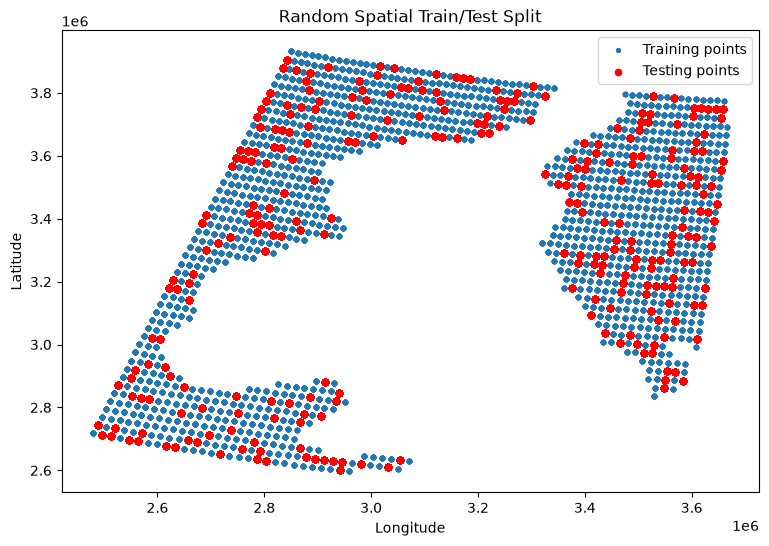

In [88]:
plt.figure(figsize=(9, 6))

plt.scatter(
    X_train["x"], X_train["y"],
    s=8, label="Training points"
)

plt.scatter(
    X_test["x"], X_test["y"],
    s=20, color="red", label="Testing points"
)

plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("Random Spatial Train/Test Split")
plt.legend()
plt.show()

In [105]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [ ]:
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import Matern, DotProduct, RBF, ExpSineSquared, ConstantKernel, WhiteKernel
from sklearn.metrics import mean_squared_error, mean_absolute_error

kernel_specs = {
    "Matern_32": (
        ConstantKernel(
            1.0,
            constant_value_bounds=(1e-3, 1e3)
        )
        * Matern(
            length_scale=1.0,
            length_scale_bounds=(1e-2, 1e2),
            nu=1.5
        )
        + WhiteKernel(
            noise_level=1.0,
            noise_level_bounds=(1e-5, 1e2)
        )
    ),

    "Matern_52": (
        ConstantKernel(
            1.0,
            constant_value_bounds=(1e-3, 1e3)
        )
        * Matern(
            length_scale=1.0,
            length_scale_bounds=(1e-2, 1e2),
            nu=2.5
        )
        + WhiteKernel(
            noise_level=1.0,
            noise_level_bounds=(1e-5, 1e2)
        )
    ),

    "RBF": (
        ConstantKernel(
            1.0,
            constant_value_bounds=(1e-3, 1e3)
        )
        * RBF(
            length_scale=1.0,
            length_scale_bounds=(1e-2, 1e2)
        )
        + WhiteKernel(
            noise_level=1.0,
            noise_level_bounds=(1e-5, 1e2)
        )
    ),

    "DotProduct": (
        ConstantKernel(
            1.0,
            constant_value_bounds=(1e-3, 1e3)
        )
        * DotProduct(
            sigma_0=1.0,
            sigma_0_bounds=(1e-3, 1e3)
        )
        + WhiteKernel(
            noise_level=1.0,
            noise_level_bounds=(1e-4, 1e2)
        )
    )
}


models = {}
predictions = {}
metrics = []

for name, kernel in kernel_specs.items():

    model = GaussianProcessRegressor(
        kernel=kernel,
        alpha=1e-4,
        normalize_y=True,
        n_restarts_optimizer=2,
        random_state=0
    )

    model.fit(X_train_scaled, y_train)

    y_pred, y_std = model.predict(
        X_test_scaled,
        return_std=True
    )

    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    mae = mean_absolute_error(y_test, y_pred)

    models[name] = model

    predictions[name] = {
        "prediction": y_pred,
        "std": y_std
    }

    metrics.append({
        "kernel": name,
        "RMSE": rmse,
        "MAE": mae,
        "log_marginal_likelihood": model.log_marginal_likelihood()
    })
    
metrics_df = pd.DataFrame(metrics).sort_values("RMSE")

metrics_df

In [93]:
y_train

22       288.899994
23       288.899994
24       288.750000
25       288.449982
26       288.000000
            ...    
87351    290.850006
87352    289.500000
87353    288.149994
87354    288.149994
87355    290.699982
Name: temperature, Length: 45252, dtype: float32

In [92]:
X_test

,x,y,time_days,water_vapor,wind_speed
27,2.940961e+06,2.599909e+06,0.0,18.599998,6.199999
52,2.877836e+06,2.640929e+06,0.0,17.399998,6.599998
55,2.929255e+06,2.629800e+06,0.0,18.599998,6.799999
56,2.946420e+06,2.626207e+06,0.0,18.899998,6.599998
58,2.980785e+06,2.619194e+06,0.0,19.199997,7.000000
...,...,...,...,...,...
87329,3.172803e+06,3.847922e+06,30.0,14.099998,7.199999
87330,3.185845e+06,3.845146e+06,30.0,14.099998,7.599998
87339,3.303624e+06,3.822147e+06,30.0,12.899998,7.599998
87347,3.527770e+06,3.788531e+06,30.0,13.799997,4.599998
